Successfully loaded 8 files from SUIM-master/data/test/images
Successfully loaded 48 files from SUIM-master/data/test/masks


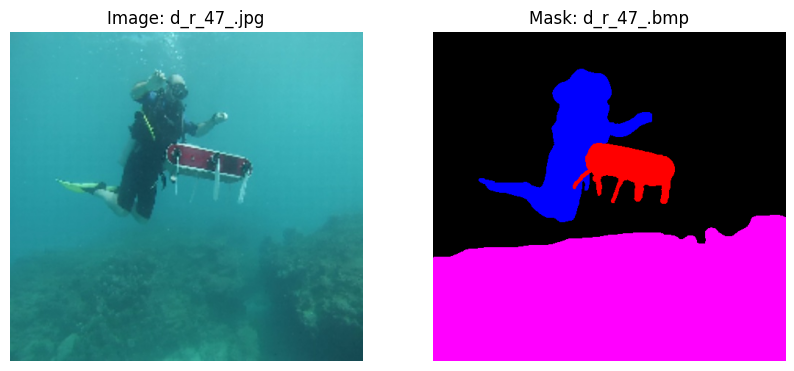

In [11]:
import os
import cv2
import matplotlib.pyplot as plt

# 1. Define the paths to your dataset folders
IMAGE_DIR = "SUIM-master/data/test/images"
MASK_DIR = "SUIM-master/data/test/masks"


def load_images_from_folder(folder_path):
    images = []
    filenames = []

    if not os.path.exists(folder_path):
        print(f"Error: The folder '{folder_path}' was not found.")
        return images, filenames

    # Walk subfolders too, since masks are grouped into category folders.
    for root, _, files in os.walk(folder_path):
        for filename in sorted(files):
            if filename.lower().endswith((".png", ".jpg", ".jpeg", ".bmp")):
                img_path = os.path.join(root, filename)
                img = cv2.imread(img_path)

                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    images.append(img)
                    filenames.append(filename)

    print(f"Successfully loaded {len(images)} files from {folder_path}")
    return images, filenames


# 2. Load your data directly from the directories
raw_images, image_names = load_images_from_folder(IMAGE_DIR)
mask_images, mask_names = load_images_from_folder(MASK_DIR)

# 3. Display a sample only when both folders contain images
if raw_images and mask_images:
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.title(f"Image: {image_names[0]}")
    plt.imshow(raw_images[0])
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.title(f"Mask: {mask_names[0]}")
    plt.imshow(mask_images[0])
    plt.axis("off")

    plt.show()
else:
    print("Cannot display a pair: no images were found in one or both folders.")